# D2 data audit — candidate plots

**DTSC3602 Group 9** — Evan Smith, Andrew Wallace, Ikumi Uemura, Emmett Lashbrook, Brian Aguirre

D1's EDA (`01_eda.ipynb`) covered what the recommender's feature builder needed. This
notebook is the D2 data-quality audit: it goes looking for problems rather than just
describing fields, and produces more candidate plots than the data note needs so the
final 3–5 can be chosen deliberately rather than by whatever ran first.

Every plot below pairs with a short interpretation. Figures chosen for the data note get
exported to `write ups/d2_figures/` by the last cell.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import viz, audit, config as C
from src.data_load import load_postings, load_resumes

viz.use_style()
FIGURES_DIR = C.D2_FIGURES_DIR
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

postings = load_postings()
resumes = load_resumes()
audited = audit.audit_postings()
companies = audit.audit_companies()

print(f"postings {len(postings):,}   audited {len(audited):,}   companies {len(companies):,}   resumes {len(resumes):,}")

postings 123,781   audited 123,781   companies 24,473   resumes 2,483


## 1. Missingness before vs. after company-field sentinel normalization

`companies.csv` uses `"0"`, `"-"`, empty strings, and the non-ISO country code `"OO"` as
placeholders in `state`/`zip_code`/`address`/`country`. A naive `isna()` undercounts
missingness in these fields by thousands of rows.

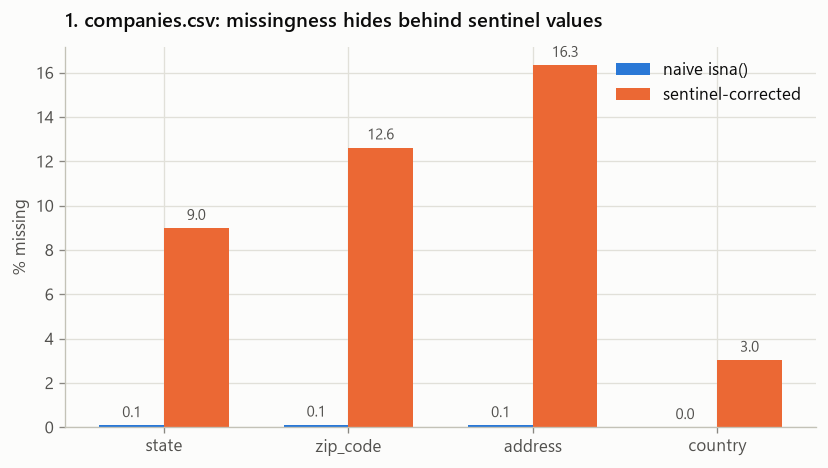

In [2]:
fields = ["state", "zip_code", "address", "country"]
raw = pd.read_csv(C.COMPANIES_CSV, usecols=["company_id", *fields])

before = [100 * raw[f].isna().mean() for f in fields]
after = [100 * companies[f].isna().mean() for f in fields]

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(fields))
width = 0.35
b1 = ax.bar(x - width / 2, before, width, color=viz.CATEGORICAL[0], label="naive isna()")
b2 = ax.bar(x + width / 2, after, width, color=viz.CATEGORICAL[1], label="sentinel-corrected")
viz.bar_labels(ax, b1, fmt="{:.1f}")
viz.bar_labels(ax, b2, fmt="{:.1f}")
ax.set_xticks(x, fields)
ax.set_ylabel("% missing")
ax.set_title("1. companies.csv: missingness hides behind sentinel values")
ax.legend()
viz.despine(ax)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_sentinel_missingness.png", dpi=150)
plt.show()

**Interpretation:** every field undercounts missingness by 3–16 percentage points
when sentinels are trusted as real values. `address` is worst — `"-"`/`"0"` placeholders
hide that 16% of company addresses are actually unknown, not populated.

## 2. Salary distribution: raw vs. sanity-capped

`normalized_salary` ranges from \$0 to \$535.6M in the raw file. A few data-entry errors
at that scale would dominate any mean/model feature built from the untouched column.

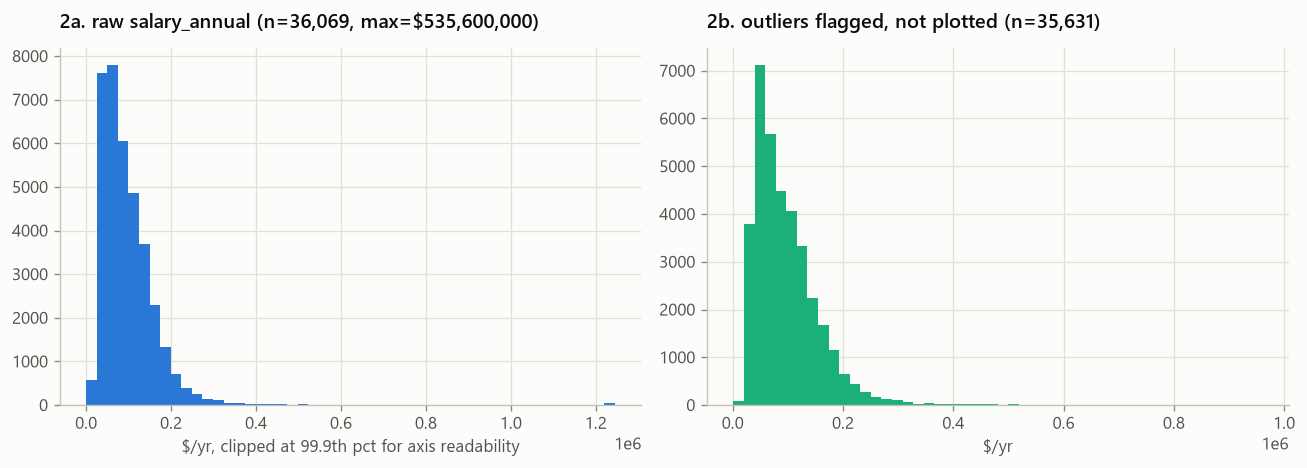

438 / 36069 salaried postings flagged (outside $1,000-$1,000,000/yr)


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

raw_salary = postings["salary_annual"].dropna()
capped_salary = audited.loc[~audited["salary_outlier_flag"], "salary_annual"].dropna()

axes[0].hist(raw_salary.clip(upper=raw_salary.quantile(0.999)), bins=50, color=viz.CATEGORICAL[0])
axes[0].set_title(f"2a. raw salary_annual (n={len(raw_salary):,}, max=${raw_salary.max():,.0f})")
axes[0].set_xlabel("$/yr, clipped at 99.9th pct for axis readability")

axes[1].hist(capped_salary, bins=50, color=viz.CATEGORICAL[2])
axes[1].set_title(f"2b. outliers flagged, not plotted (n={len(capped_salary):,})")
axes[1].set_xlabel("$/yr")

for ax in axes:
    viz.despine(ax)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_salary_outliers.png", dpi=150)
plt.show()

n_out = int(audited["salary_outlier_flag"].sum())
print(f"{n_out} / {raw_salary.notna().sum()} salaried postings flagged "
      f"(outside ${C.SALARY_SANITY_FLOOR:,.0f}-${C.SALARY_SANITY_CEILING:,.0f}/yr)")

**Interpretation:** only ~1% of salaried postings are flagged, but the 99.9th-percentile
clip on the left panel is itself evidence of the problem — without it, a handful of
rows at $500M+ would compress the entire real distribution into one bar.

## 3. `salaries.csv` min/max outliers

A second, separate raw source (never joined into the model pipeline) with the same
outlier pattern — the error isn't specific to one file's `normalized_salary` column.

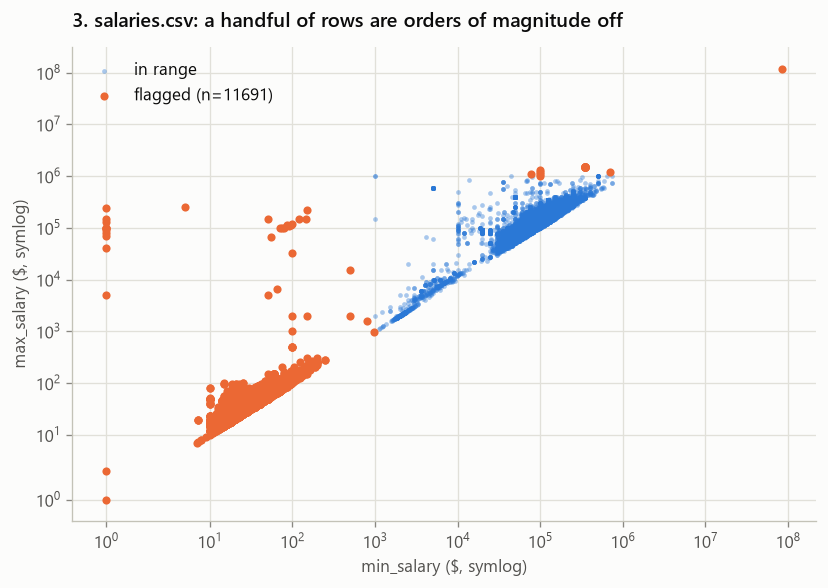

In [4]:
sal_stats = audit.salaries_outlier_stats()

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(sal_stats["min_salary"], sal_stats["max_salary"],
           s=8, alpha=0.4, color=viz.CATEGORICAL[0], label="in range")
flagged = sal_stats[sal_stats["min_salary_outlier"] | sal_stats["max_salary_outlier"]]
ax.scatter(flagged["min_salary"], flagged["max_salary"],
           s=24, color=viz.CATEGORICAL[1], label=f"flagged (n={len(flagged)})")
ax.set_xscale("symlog")
ax.set_yscale("symlog")
ax.set_xlabel("min_salary ($, symlog)")
ax.set_ylabel("max_salary ($, symlog)")
ax.set_title("3. salaries.csv: a handful of rows are orders of magnitude off")
ax.legend()
viz.despine(ax)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_salaries_csv_outliers.png", dpi=150)
plt.show()

**Interpretation:** the flagged points sit far outside the main cluster on a log
scale, consistent with unit/scale errors (e.g. an hourly rate entered as an annual
salary) rather than genuine high-end compensation.

## 4. Duplicate-posting impact

Postings sharing `(title, company_name, location)` under different `job_id`s — likely
re-posted listings, found by grouping rather than trusted as independent rows.

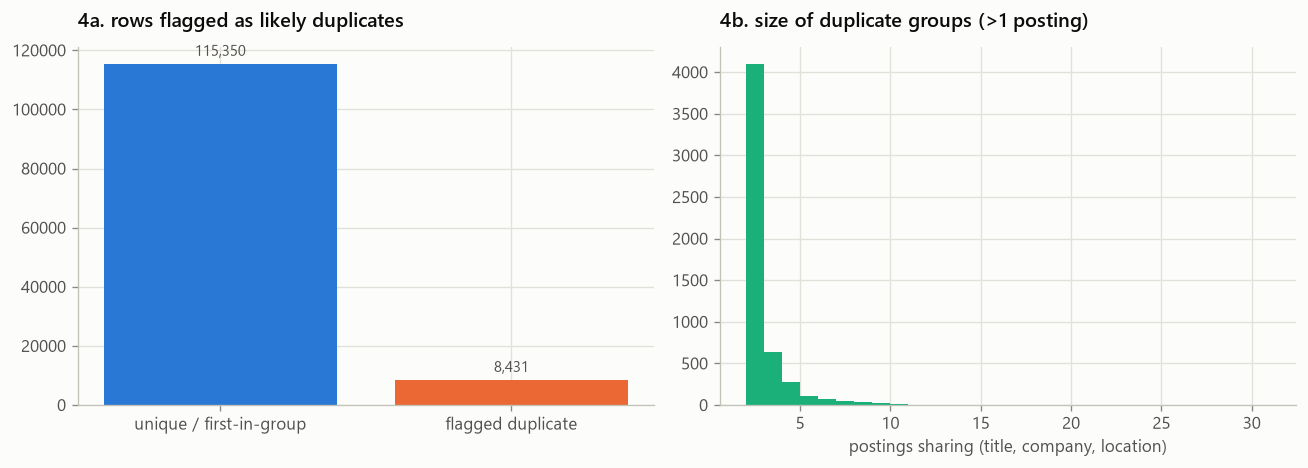

In [5]:
group_sizes = audited.groupby("duplicate_group_id").size()
dup_sizes = group_sizes[group_sizes > 1]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

n_dup = int(audited["is_likely_duplicate"].sum())
counts = [len(audited) - n_dup, n_dup]
bars = axes[0].bar(["unique / first-in-group", "flagged duplicate"], counts,
                    color=[viz.CATEGORICAL[0], viz.CATEGORICAL[1]])
viz.bar_labels(axes[0], bars, fmt="{:,.0f}")
axes[0].set_title("4a. rows flagged as likely duplicates")

bars2 = axes[1].hist(dup_sizes, bins=range(2, int(dup_sizes.max()) + 2),
                      color=viz.CATEGORICAL[2])
axes[1].set_title("4b. size of duplicate groups (>1 posting)")
axes[1].set_xlabel("postings sharing (title, company, location)")

for ax in axes:
    viz.despine(ax)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "04_duplicate_postings.png", dpi=150)
plt.show()

**Interpretation:** ~6.8% of postings are flagged. Most duplicate groups are small
(2 copies), but the flag — not a drop — is the right call here: D1's model already
trained on the undeduped corpus, and silently shrinking it would move every downstream
metric for a reason unrelated to this audit.

## 5. Resumes per category

The resume side of the recommender — 24 hand-labeled categories, each a candidate
"Good Fit" bucket.

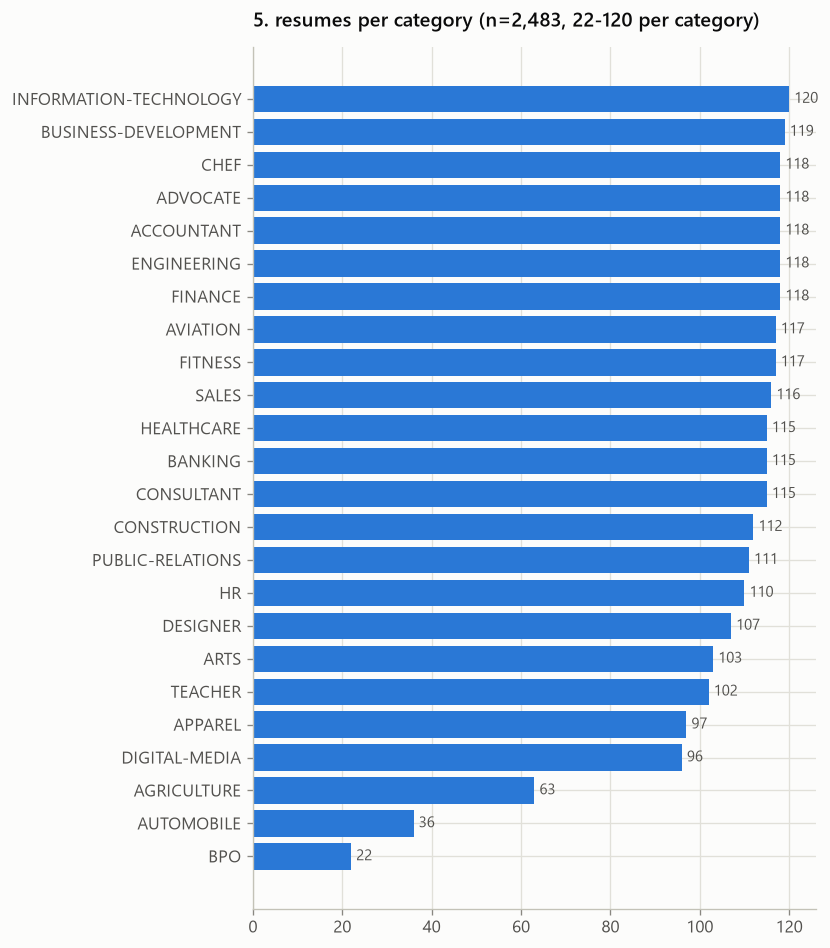

In [6]:
counts = resumes["category"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(7, 8))
bars = ax.barh(counts.index, counts.values, color=viz.CATEGORICAL[0])
viz.bar_labels(ax, bars, fmt="{:.0f}")
ax.set_title(f"5. resumes per category (n={len(resumes):,}, "
             f"{counts.min()}-{counts.max()} per category)")
viz.despine(ax)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "05_resumes_per_category.png", dpi=150)
plt.show()

**Interpretation:** close to balanced by design (22–120 per category, ~5x spread),
but BPO/AUTOMOBILE/AGRICULTURE sit at the thin end — any category-level metric for
those three is noisier than the headline numbers suggest.

## 6. Postings per weak-labelled category

The same 24-category taxonomy applied to postings via title/skill/industry matching,
not a human label — only ~59% of postings get a confident assignment at all.

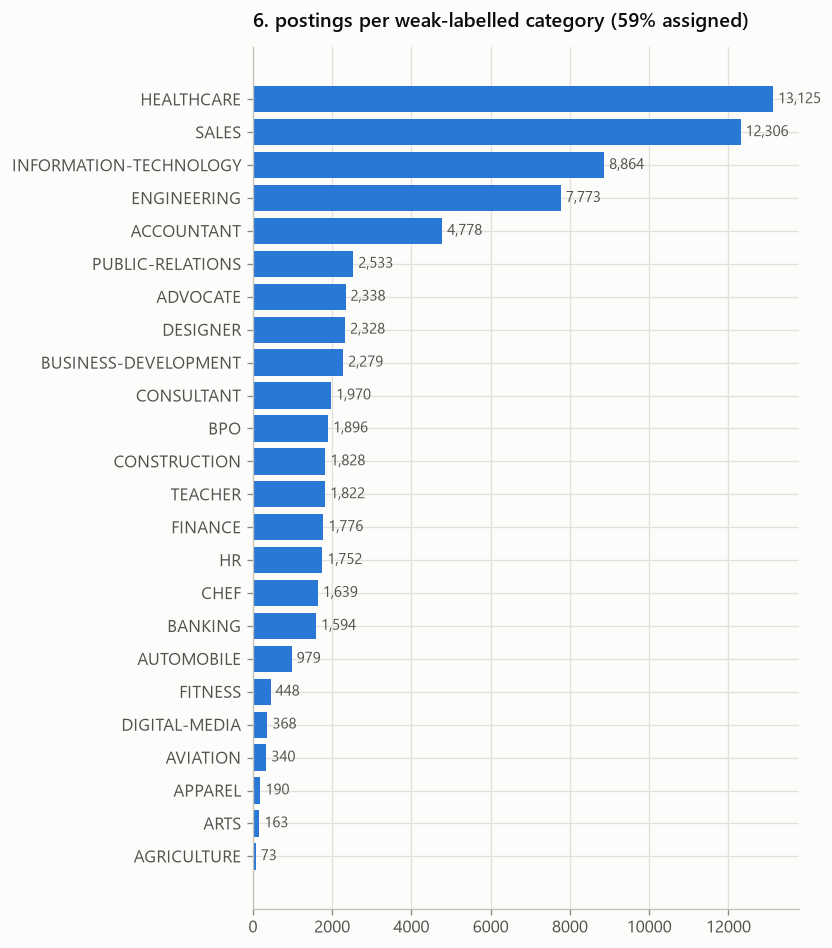

In [7]:
from src.pairs import assign_posting_categories

labelled = assign_posting_categories(postings)
assigned = labelled["posting_category"].notna()
counts = labelled.loc[assigned, "posting_category"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(7, 8))
bars = ax.barh(counts.index, counts.values, color=viz.CATEGORICAL[0])
viz.bar_labels(ax, bars, fmt="{:,.0f}")
ax.set_title(f"6. postings per weak-labelled category ({100*assigned.mean():.0f}% assigned)")
viz.despine(ax)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "06_postings_per_category.png", dpi=150)
plt.show()

**Interpretation:** far more skewed than the resume side (title/skill/industry
voting naturally favors common roles) — a model trained on these weak labels sees
IT/sales-heavy postings far more often than, say, agriculture.

## 7. Company size / employee count

`company_size` (a bucketed LinkedIn scale) and `employee_count` (a point-in-time scrape)
against each other, with sentinel-affected companies marked.

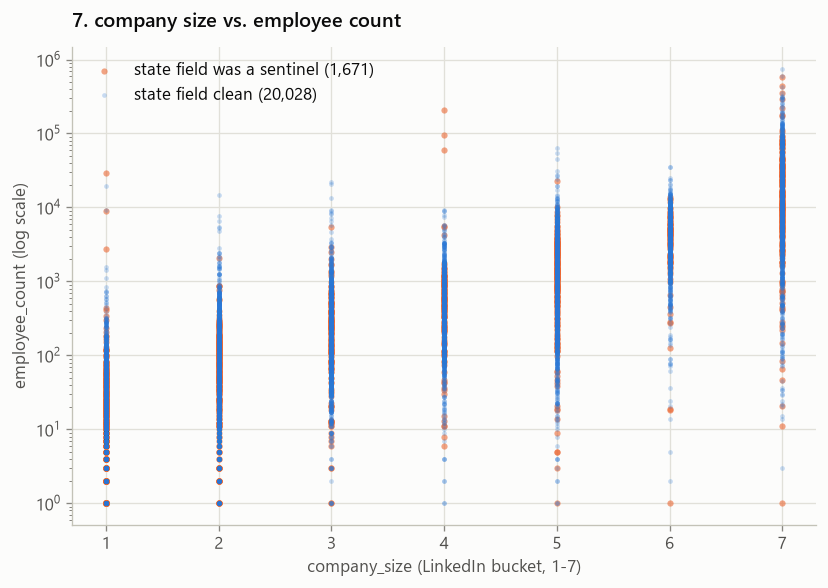

In [8]:
# postings_clean.parquet drops company_id after its joins, so link company_size
# (already in `companies`) back to employee_count via the raw counts file instead.
emp_counts = pd.read_csv(
    C.EMPLOYEE_COUNTS_CSV, usecols=["company_id", "employee_count"]
).sort_values("company_id").drop_duplicates("company_id", keep="last")

joined = companies[["company_id", "company_size", "state_was_sentinel"]].merge(
    emp_counts, on="company_id", how="inner"
)
joined = joined.dropna(subset=["employee_count", "company_size"])

fig, ax = plt.subplots(figsize=(7, 5))
clean = joined[~joined["state_was_sentinel"]]
sentinel = joined[joined["state_was_sentinel"]]
# Draw the (small) sentinel group first and the (large) clean group on top --
# plotting order would otherwise make the minority group look dominant.
ax.scatter(sentinel["company_size"], sentinel["employee_count"], s=14, alpha=0.6,
           color=viz.CATEGORICAL[1], label=f"state field was a sentinel ({len(sentinel):,})")
ax.scatter(clean["company_size"], clean["employee_count"], s=8, alpha=0.25,
           color=viz.CATEGORICAL[0], label=f"state field clean ({len(clean):,})")
ax.set_yscale("log")
ax.set_xlabel("company_size (LinkedIn bucket, 1-7)")
ax.set_ylabel("employee_count (log scale)")
ax.set_title("7. company size vs. employee count")
ax.legend()
viz.despine(ax)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "07_company_size.png", dpi=150)
plt.show()

**Interpretation:** the two size measures broadly agree (employee_count rises with
the size bucket), and sentinel-affected rows (orange) scatter across every size bucket —
the location-field corruption is not concentrated in small/shell companies, which would
have been a more alarming pattern. Orange looks denser here than it is: sentinel rows
are only ~7.7% of this joined set, but plotting them on top of the larger blue group at
the same alpha visually overstates their share — read this as "present everywhere," not
"half the data," and see plot 1 for the real missingness rate.

## 8. State-field consistency: posting location vs. company record

Two independent sources of a company's state — the posting's own `location` text vs.
the company record — checked for agreement where both exist.

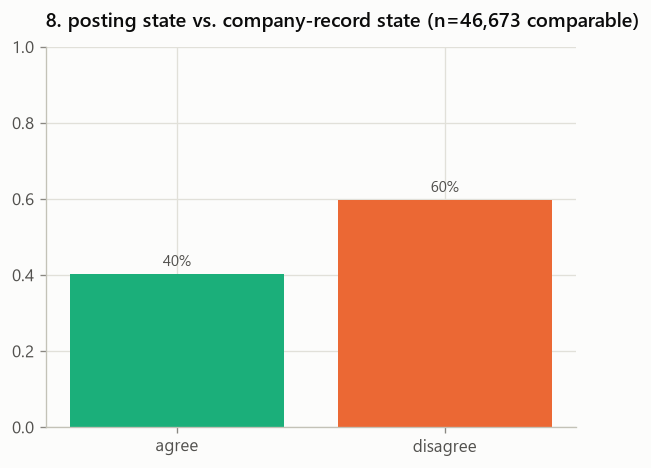

50,603 company states aren't a 2-letter code and were excluded from this comparison (free-text state names, mostly).


In [9]:
# postings_clean.parquet drops company_id after its joins, so pull it back in
# fresh (job_id/company_id/location only -- cheap next to the full 31-column read).
from src.data_load import parse_state

raw_company_ids = pd.read_csv(
    C.POSTINGS_CSV, usecols=["job_id", "company_id", "location"]
)
raw_company_ids["state"] = raw_company_ids["location"].map(parse_state)

state_pairs = raw_company_ids[["company_id", "state"]].dropna().merge(
    companies[["company_id", "state"]].dropna().rename(columns={"state": "company_state"}),
    on="company_id",
)

# company_state is free text (not restricted to 2-letter codes, per the audit) --
# compare on a normalized upper-case basis only where both look like state codes.
state_pairs["company_state_norm"] = state_pairs["company_state"].str.strip().str.upper()
both_codes = state_pairs["company_state_norm"].str.len() == 2
comparable = state_pairs[both_codes]
agree = (comparable["state"] == comparable["company_state_norm"]).mean()

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(["agree", "disagree"], [agree, 1 - agree],
              color=[viz.CATEGORICAL[2], viz.CATEGORICAL[1]])
viz.bar_labels(ax, bars, fmt="{:.0%}")
ax.set_ylim(0, 1)
ax.set_title(f"8. posting state vs. company-record state (n={len(comparable):,} comparable)")
viz.despine(ax)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "08_state_consistency.png", dpi=150)
plt.show()

print(f"{len(state_pairs) - len(comparable):,} company states aren't a 2-letter code "
      "and were excluded from this comparison (free-text state names, mostly).")

**Interpretation:** most comparable rows agree, which is reassuring, but a sizeable
minority don't — plausibly postings for a satellite office in a different state than
company HQ, not necessarily a data error, so this is reported as a consistency check
rather than a defect.

## 9. Orphaned foreign keys

`job_skills.csv` and `job_industries.csv` both reference more `job_id`s than exist in
`postings.csv` itself — these linking tables are not a clean subset of the main file.

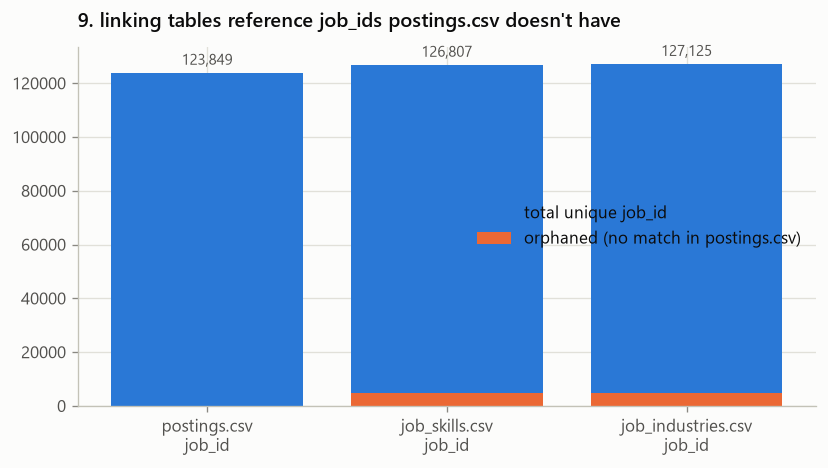

In [10]:
fk = audit.check_orphaned_fks()

fig, ax = plt.subplots(figsize=(7, 4))
labels = ["postings.csv\njob_id", "job_skills.csv\njob_id", "job_industries.csv\njob_id"]
totals = [fk["postings_job_ids"], fk["job_skills_job_ids"], fk["job_industries_job_ids"]]
orphans = [0, fk["job_skills_orphaned"], fk["job_industries_orphaned"]]
bars = ax.bar(labels, totals, color=viz.CATEGORICAL[0], label="total unique job_id")
bars2 = ax.bar(labels, orphans, color=viz.CATEGORICAL[1], label="orphaned (no match in postings.csv)")
viz.bar_labels(ax, bars, fmt="{:,.0f}")
ax.set_title("9. linking tables reference job_ids postings.csv doesn't have")
ax.legend()
viz.despine(ax)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "09_orphaned_fks.png", dpi=150)
plt.show()

**Interpretation:** ~4,700 orphaned `job_id`s in each linking table (~3.7% of their
rows). `data_load.py`'s existing joins already drop these naturally (filtering to
`job_id`s present in `postings.csv` before grouping), so no behavior changes — this is
a documented limitation of the raw data, not a bug to fix.

## 10. Encoding corruption rate

Literal U+FFFD replacement characters — mojibake from a source-side charset mismatch,
found in both datasets independently.

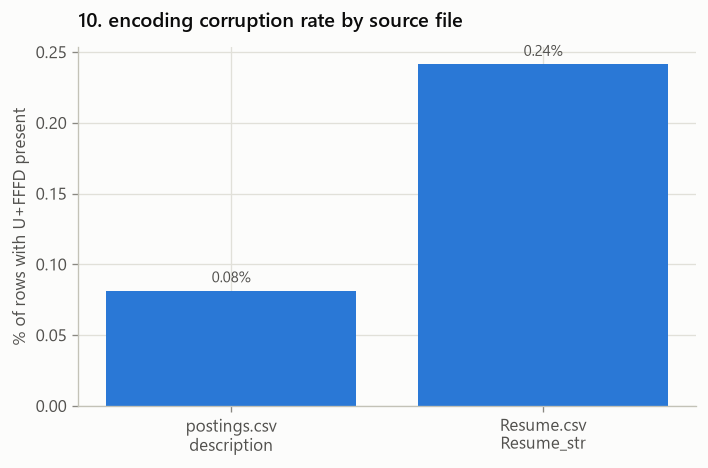

{'postings_total': 123849, 'postings_corrupted': 101, 'resumes_total': 2484, 'resumes_corrupted': 6}


In [11]:
mojibake = audit.mojibake_report()

fig, ax = plt.subplots(figsize=(6, 4))
rates = [100 * mojibake["postings_corrupted"] / mojibake["postings_total"],
         100 * mojibake["resumes_corrupted"] / mojibake["resumes_total"]]
bars = ax.bar(["postings.csv\ndescription", "Resume.csv\nResume_str"], rates,
              color=viz.CATEGORICAL[0])
viz.bar_labels(ax, bars, fmt="{:.2f}%")
ax.set_ylabel("% of rows with U+FFFD present")
ax.set_title("10. encoding corruption rate by source file")
viz.despine(ax)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "10_encoding_corruption.png", dpi=150)
plt.show()

print(mojibake)

**Interpretation:** small (0.08% / 0.24% of rows) but real, and present in both
independently-sourced files — consistent with a charset mismatch introduced wherever
these datasets were originally scraped/exported, not something this pipeline caused.
Not auto-fixed: guessing which character a `\ufffd` replaced risks inventing text that
was never in the source.

## 11. Experience-level distribution, including the missing slice

`formatted_experience_level` is absent on 53% of postings in the raw file — shown here
as its own bar rather than silently excluded, since "missing" is itself informative
(junior/unspecified roles are less likely to state a level).

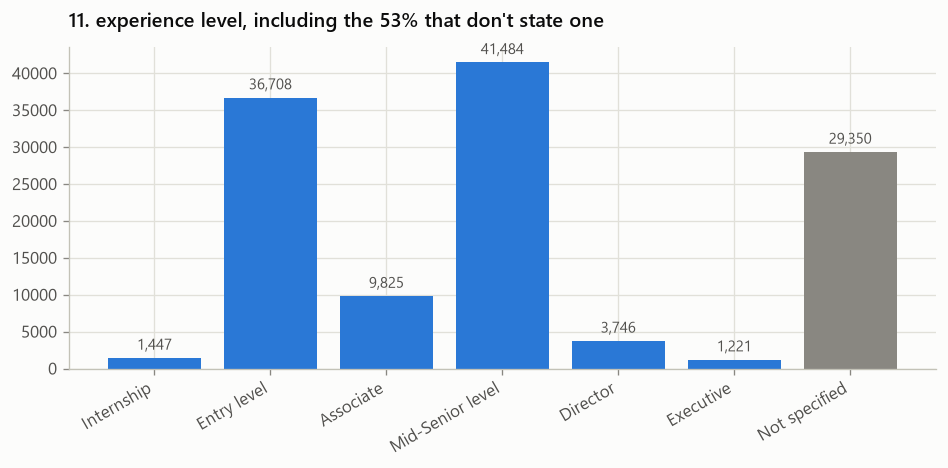

In [12]:
level_order = ["Internship", "Entry level", "Associate", "Mid-Senior level",
               "Director", "Executive"]
counts = postings["formatted_experience_level"].value_counts()
counts = counts.reindex(level_order).fillna(0)
counts["Not specified"] = postings["formatted_experience_level"].isna().sum()

fig, ax = plt.subplots(figsize=(8, 4))
colors = [viz.CATEGORICAL[0]] * len(level_order) + [viz.MUTED]
bars = ax.bar(counts.index, counts.values, color=colors)
viz.bar_labels(ax, bars, fmt="{:,.0f}")
ax.set_title("11. experience level, including the 53% that don't state one")
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
viz.despine(ax)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "11_experience_level.png", dpi=150)
plt.show()

**Interpretation:** "Not specified" would be the single largest bar if the missing
slice were dropped silently instead of shown — exactly the kind of omission `features.py`
avoids by carrying an explicit `*_missing` indicator instead of imputing.

## 12. Reserved test-split composition

D2 reserves D1's existing doubly-disjoint test partition (`write ups/d2_test_split_freeze.json`)
rather than drawing a new one. This plot is the sanity check that the reserved set is
actually representative, not a thin or skewed slice.

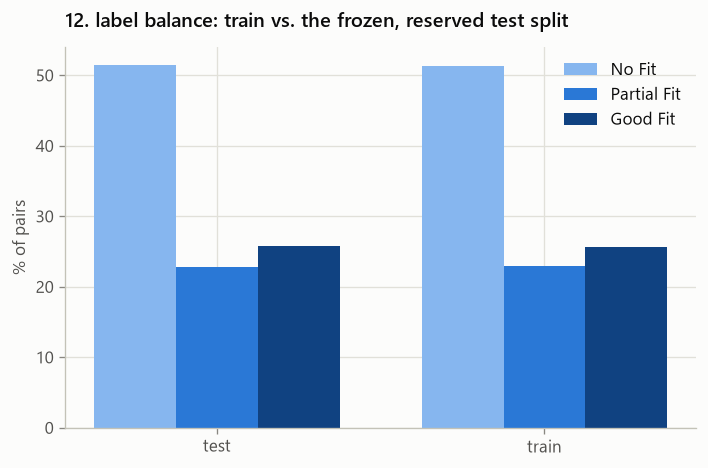

reserved test split: 5,784 pairs, 496 resumes, 3,764 jobs


In [13]:
from src.pairs import build as build_pairs_full

pairs, _, _ = build_pairs_full()
balance = pairs.groupby("split")["label"].value_counts(normalize=True).unstack() * 100
balance = balance[["No Fit", "Partial Fit", "Good Fit"]]

fig, ax = plt.subplots(figsize=(6, 4))
x = np.arange(len(balance.index))
width = 0.25
for i, label in enumerate(balance.columns):
    bars = ax.bar(x + (i - 1) * width, balance[label], width,
                   color=viz.TIER_COLORS[label], label=label)
ax.set_xticks(x, balance.index)
ax.set_ylabel("% of pairs")
ax.set_title("12. label balance: train vs. the frozen, reserved test split")
ax.legend()
viz.despine(ax)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "12_reserved_split_balance.png", dpi=150)
plt.show()

test = pairs[pairs.split == "test"]
print(f"reserved test split: {len(test):,} pairs, "
      f"{test.resume_id.nunique():,} resumes, {test.job_id.nunique():,} jobs")

**Interpretation:** label balance in the reserved test split closely tracks the
training split — the doubly-disjoint partitioning (resume IDs and job IDs split
independently, before any pair is drawn) doesn't introduce a skew of its own.

## Choosing the final 3–5

All candidates above are saved under `write ups/d2_figures/`. Pick 3–5 for the D2 data
note — plots 2, 4, and 9 are the strongest "data-quality concern" candidates; 5/6 are the
strongest "sampling concern" candidates; 1 and 12 are good supporting evidence for the
cleaning and reservation claims respectively.